[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ichristov/intermediate-fluid-mechanics/blob/main/slipper_pad_bearing.ipynb)


# LEARNING OBJECTIVE

After exploring this notebook, you will be able to analyze Poiseuille&ndash;Couette (PC) flow underneath a slipper pad bearing using lubrication theory. This notebook builds on the previous demonstration of unidirectional PC flow in a straight channel. The velocity profile and the nonlinear pressure distribution generated by the lubrication flow are visualized.

# PRELIMINARIES

[run the next cell to setup Python environment customizations and load packages]

In [2]:
# interactive plots setup
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

# sympy setup
import sympy as sp
sp.init_printing()
from sympy.vector import *
from IPython.display import display, Math

# plotting customizations
from matplotlib import pyplot as plt
import matplotlib.patches as patches
size=16
params = {'legend.fontsize': 'large',
#          'figure.figsize': (20,8),
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.875,
          'ytick.labelsize': size*0.875,
          'axes.titlepad': 25}
plt.rcParams.update(params)
%matplotlib inline

# numerics
import numpy as np

# for Colab only: to save plots as files and download them
#from google.colab import files

## Credit

Initial version written by [Ivan C. Christov](http://christov.tmnt-lab.org), Purdue University.

# FLOW GENERATED UNDER A MOVING SLIPPER PAD

Consider a rigid 2D slipper pad (extending infinitely out of the page). The characteristic height of the fluid layer under the slipper pad is $h_0$, the height of the fluid layer at the pad's trailing edge, $x^*=0$. 

The distance between the lower rigid wall and the slipper pad bottom side is $h^*(x^*) = h(x)/h_0$ (actual function will be specified below) and $x^*=x/L$. The axial length of the slipper pad is $L$. The pressure before and beyond the slipper pad is uniform and equal to $p_0$. 

The slipper pad is constrained to move only horizontally and we are solving the problem in the absolute coordinate frame attached to the stationary lower wall (these are **key** facts in how we proceed below!). Since the pad moves in the $+x$ direction, $x^*=1$ is its leading edge.

## Governing equations

The dimensional lubrication equations are
\begin{alignat*}{3}
    \text{[COM]}\qquad &&\frac{\partial v_x}{\partial x} + \frac{\partial v_y}{\partial y} &= 0,\\
    \text{[COLM-$x$]}\qquad &&0 &\approx -\frac{\partial p}{\partial x} + \mu \frac{\partial^2 v_x}{\partial y^2},\\
    \text{[COLM-$y$]}\qquad &&0 &\approx -\frac{\partial p}{\partial y}.
\end{alignat*}
The boundary conditions (no slip, no penetration, uniform pressure outside the slipper pad) are
\begin{align*}
    v_x(x,y=0) &= 0,\\
    v_y(x,y=0) &= 0.\\
    v_x\big(x,y=h(x)\big) &= V_{x} = \text{given const.},\\
    v_y\big(x,y=h(x),t\big) &= \frac{D h}{D t},\\
    p(x=0,y) &= p_0,\\
    p(x=L,y) &= p_0.
\end{align*}

## The horizontal velocity

The solution of COLM-$x$ subject to these boundary conditions is once again the combined Poiseuille&ndash;Couette flow, but with $h=h(x)$:
$$
    v_x(x,y) = \frac{[h(x)]^2}{2\mu}\left(-\frac{\partial p}{\partial x}\right) \left\{ \frac{y}{h(x)} - \left[\frac{y}{h(x)}\right]^2 \right\} + V_{x} \frac{y}{h(x)},
$$
where the pressure $p(x)$ is currently unknown. We'll keep using partial derivatives for clarity, but most quantities are only functions of $x$.

## The vertical velocity

From COM, we have
\begin{align*}
    v_y(x,y) &= - \int_0^y \frac{\partial v_x}{\partial x} d\tilde{y} \\
           &= \frac{V_{x}}{2} \left[\frac{y}{h(x)}\right]^2 \frac{\partial h}{\partial x}
           - \frac{1}{2\mu} \left(-\frac{\partial^2 p}{\partial x^2}\right)\left[h(x) \frac{y^2}{2} - \frac{y^3}{3} \right]
           - \frac{1}{4\mu} \left(-\frac{\partial p}{\partial x}\right) \frac{\partial h}{\partial x} y^2 
\end{align*}

## The kinematic BC

Repeating the step for finding $v_y$, but integrating all the way to $y=h(x)$ and using the boundary condition, we get
\begin{align*}
    V_{y} &= - \int_0^{h(x)} \frac{\partial v_x}{\partial x} \,dy \\
      &\overbrace{=}^{\text{Leibniz}} - \frac{\partial }{\partial x} \int_0^{h(x)} v_x(x,y) \,dy + \underbrace{v_x\big(x,y=h(x)\big)}_{V_{x}}\frac{\partial h}{\partial x} \\
      &= - \frac{\partial }{\partial x} \left\{ V_{x} \frac{h(x)}{2} - \frac{[h(x)]^3}{12\mu} \frac{\partial p}{\partial x} \right\} + V_{x} \frac{\partial h}{\partial x} \\
      &= \frac{\partial }{\partial x} \left\{ \frac{[h(x)]^3}{12\mu} \frac{\partial p}{\partial x} \right\} + \frac{V_{x}}{2} \frac{\partial h}{\partial x}.
\end{align*}

**Important:** the vertical velocity, $V_y$ at the angled surface of the block is not an independent quantity. It is constrained by the _kinematic boundary condition_ [(Hunt & Webb, 2026)](https://doi.org/10.1119/5.0298780):
$$
    V_y = \frac{D h}{D t} = \frac{\partial h}{\partial t} + V_x \frac{\partial h}{\partial x} \qquad\qquad [\text{all evaluated at $y=h(x)$}].
$$

Is $h$ changing with $t$!? Yes, but _in a very constrained way_. In the absolute frame the slipper pad translates horizontally, so an observer standing on the stationary lower wall sees a time-changing gap height as the slipper passes by. Such a "traveling" gap can be expressed in terms of a traveling coordinate $\xi = x-V_x t$ as $h(x,t) = h(\xi)$ only. Taking derivatives and using the chain rule gives $\partial h/\partial t = -V_x\,\partial h/\partial x$, which means that
$$
    \frac{\partial h}{\partial t} + V_x \frac{\partial h}{\partial x} = -V_x \frac{\partial h}{\partial x} + V_x \frac{\partial h}{\partial x} \qquad \frac{D h}{D t} = V_y = 0.
$$

With these kinematics established, we now treat the flow at a fixed instant (equivalently, in a frame moving with the block), so the derivation below is written in terms of $x$ only and the explicit $t$ dependence is omitted.

## The pressure

With this information, $V_y=0$, in hand, the equation 
$$
    V_y = \underbrace{\frac{\partial }{\partial x} \left\{ \frac{[h(x)]^3}{12\mu} \frac{\partial p}{\partial x} \right\} + \frac{V_{x}}{2} \frac{\partial h}{\partial x} = 0}_{\text{Reynolds' lubrication equation (!)}}
$$
can be integrated once:
$$
    - \frac{V_{x}}{2} h(x) = \frac{[h(x)]^3}{12\mu}\frac{\partial p}{\partial x} + C_1,
$$
or
$$
    \frac{12\mu}{[h(x)]^3} \left[ - \frac{V_{x}}{2} h(x) - C_1 \right] = \frac{\partial p}{\partial x},
$$
or
$$
    p(x) = \int_0^x \frac{12\mu}{[h(\tilde{x})]^3} \left[ - \frac{V_{x}}{2} h(\tilde{x}) - C_1 \right] d\tilde{x} + p_0.
$$
Note that $C_1$ is truly a _constant_, not a function, of integration, since $\partial p/\partial y=0$.

### Making it dimensionless

Let's make the result dimensionless:
$$
    p^*(x^*) = \frac{p(x) - p_0}{\mu V_{x} L/h_0^2} = 12\int_0^{x^*} \frac{1}{[h^*(\tilde{x}^*)]^3} \left[  - \frac{1}{2}h^*(\tilde{x}^*) - C_1^* \right] d\tilde{x}^*.
$$
Here, $x^* = x/L$ and $h^*(x^*) = h(x)/h_0$. 

**Note:** We implicitly assumed $V_x > 0$ when we divided by it, so the interpretation of the results below is that $V_x > 0$.

The pressure is subject to the final boundary condition $p^*(1) = 0$, thus
$$
    C_1^* = - \frac{\int_0^1 \frac{1}{2[h^*(x^*)]^2} dx^*}{\int_0^1 \frac{1}{[h^*(x^*)]^3} dx^*}.
$$

# PRESSURE FOR GIVEN GAP SHAPE

In [3]:
xs, xsm, xt, ys, C1s, alpha = sp.symbols('x^*, x_m^*, xtilde, y^*, C_1^*, alpha')
hs = 1 + alpha*xs
hs

Starting with the given $h^*(x^*)$ and the formulas above, evaluate $C_1^*$:

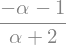

In [4]:
C1s = sp.integrate(-1/(2*hs**2), (xs, 0, 1)) \
      / sp.integrate(1/hs**3, (xs, 0, 1))
C1s.simplify()

and $p^*(x^*)$:

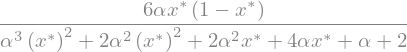

In [5]:
# need to introduce dummy variable xtilde for integration
ps = 12*sp.integrate(((-hs/2-C1s)/hs**3).subs(xs, xt), (xt, 0, xs)).simplify()
ps

The pressure reaches an extremum (maximum or minimum) value at $x^*=x^*_m$ such that $(d p^*/d x^*)|_{x^*=x_m}=0$. We compute it to find that it only depends on $\alpha$:

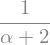

In [6]:
xsm = sp.solve(sp.Eq(ps.diff(xs), 0), xs)[0]
xsm

And the extremum pressure value $p^*_m = p^*(x^*_m)$ depends on $\alpha$:

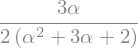

In [7]:
ps.subs(xs, xsm).simplify()

Also, we define the velocity components symbolically from our formulas above; the expressions are a bit ugly.

In [8]:
vxs = (ys/hs) + (1/2)*(hs**2)*(-ps.diff(xs))*(ys/hs - (ys/hs)**2)
vys = (1/2)*((ys/hs)**2)*hs.diff(xs) - (1/2)*(-ps.diff(xs, 2))*(hs*(ys**2)/2-(ys**3)/3) \
      - (1/2)*(-ps.diff(xs))*hs.diff(xs)*(ys**2)/2

Next, we check our work symbolically with SymPy. The last check confirms that $Dh^*/Dt^*=0$ for a traveling gap.

In [9]:
# check BCs on symbolic expressions
# got a little fancy with display Math here ...
display(Math(r'\text{checking}~~~~p^*~\text{at}~x^*=0~~~~~~:~' +
             sp.latex(ps.subs(xs, 0))))
display(Math(r'\text{checking}~~~~p^*~\text{at}~x^*=1~~~~~~:~' +
             sp.latex(ps.subs(xs, 1))))
display(Math(r'\text{checking}~~~~v_x^*~\text{at}~y^*=0~~~~~~:~' +
             sp.latex(vxs.subs(ys, 0))))
display(Math(r'\text{checking}~~~~v_x^*~\text{at}~y^*=h^*~~~~:~' +
             sp.latex(vxs.subs(ys, hs))))
display(Math(r'\text{checking}~~~~v_y^*~\text{at}~y^*=0~~~~~~:~' +
             sp.latex(vys.subs(ys, 0))))
display(Math(r'\text{checking}~~~~v_y^*~\text{at}~y^*=h^*~~~~:~' +
             sp.latex(vys.subs(ys, hs).simplify())))
# check kinematic BC with the traveling gap h*(x* - t*)
ts = sp.symbols('t^*')
hst = hs.subs(xs, xs - ts)
display(Math(r'\text{checking}~~~~\frac{D h^*}{D t^*}=\frac{\partial h^*}{\partial t^*}' +
             r'+v_x^*\frac{\partial h^*}{\partial x^*}~~~~:~' +
             sp.latex((hst.diff(ts) + vxs.subs(ys, hs).subs(xs, xs - ts)*hst.diff(xs)).simplify())))
# check COM with symbolic expressions
display(Math(r'\text{checking}~~~~\frac{\partial v_x^*}{\partial x^*}' + 
             r'+\frac{\partial v_y^*}{\partial y^*}~~~~~~~:~' +
             sp.latex((vxs.diff(xs) + vys.diff(ys)).simplify())))
# check COLM with symbolic expressions
display(Math(r'\text{checking}~~~~-\frac{\partial p^*}{\partial x^*}' +
             r'+\frac{\partial^2 v_x^*}{\partial y^{*2}}:~' +
             sp.latex((-ps.diff(xs) + vxs.diff(ys, 2)).simplify())))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Finally, we [`lambdify`](https://docs.sympy.org/latest/modules/utilities/lambdify.html) our functions for evaluation and plotting.

In [10]:
lam_h = sp.lambdify([xs, alpha], hs)

lam_p = sp.lambdify([xs, alpha], ps)

lam_vx = sp.lambdify([xs, ys, alpha], vxs)
lam_vy = sp.lambdify([xs, ys, alpha], vys)

# VISUALIZATION

In [11]:
def plot_func(α):
    # x^* goes from 0 to 1
    xp = np.linspace(0, 1, num=100)

    fig, ax = plt.subplots(tight_layout=True)

    ax.set_ylabel('$h^*(x^*) = h(x)/h_0$')
    ax.set_ylim(-3, 2)
    ax.set_xlabel('$x^* = x/L$')
    ax.set_xlim(0, 1)
    ax.plot(xp, lam_h(xp, α), linewidth=2, color='gray', linestyle='dashed')

    ax2 = ax.twinx()
    ax2.set_ylabel(r'$p^*(x^*) = \frac{p(x) - p_0}{\mu V_{x} L/h_0^2}$')
    ax2.set_ylim(-5, 5)  # might have to be judicious

    ax2.plot(xp, 0*xp, linestyle='dotted', linewidth=1, color='black')
    ax2.plot(xp, lam_p(xp, α), linewidth=2, color="brown")

    # show a grid to make it easier to see where the y=0 interface is
    ax.grid(alpha=0.5, linestyle='dotted')

    plt.show()

First, a static plot.

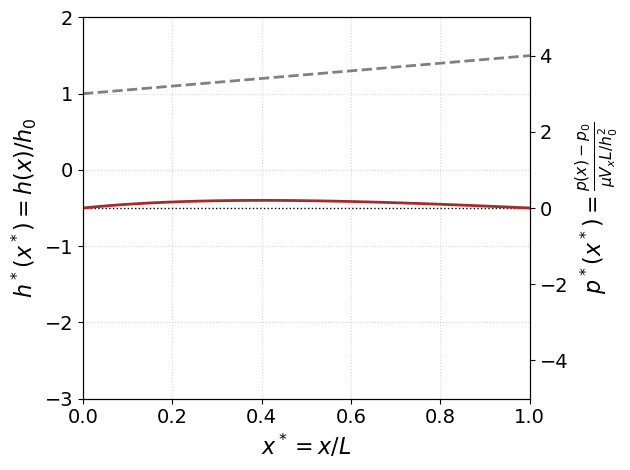

In [12]:
plot_func(0.5)

Next, an [`interact`](https://ipywidgets.readthedocs.io/en/latest/examples/Using%20Interact.html) widget will let us vary $\alpha$.

In [13]:
interact(plot_func, 
         α=widgets.FloatSlider(value=0.5, min=-0.9, max=2, step=0.05, description='Slope α'));

Finally, let's check out the velocity vector ([`quiver`](https://matplotlib.org/stable/gallery/images_contours_and_fields/quiver_simple_demo.html)) plot under the slipper pad.

In [14]:
def plot_func_vel(α):
    xp, yp = np.meshgrid(np.linspace(0.1, 0.8, num=5),
                         np.linspace(0, 2, num=25))
    qs = 4  # scaling factor for quiver plot

    # y^* goes from 0 to h^* but we'll mask the values > h^* later
    mask = yp > lam_h(xp, α)

    vx = np.ma.masked_array(lam_vx(xp, yp, α), mask)
    vy = np.ma.masked_array(lam_vy(xp, yp, α), mask)

    fig, ax = plt.subplots(tight_layout=True)

    ax.set_ylabel('$y^* = y/h_0$')
    ax.set_ylim(0, 2)
    ax.set_xlabel('$x^* = x/L$')
    ax.set_xlim(0, 1)

    ax.quiver(xp, yp, vx, vy,
              scale=qs, scale_units='xy', color='blue', zorder=2)

    # show the slipper pad
    vertices = [(0, 1), (0, 2), (1, 2), (1, lam_h(1, α))]
    polygon = patches.Polygon(vertices, closed=True, fill=False, hatch='///')
    ax.add_patch(polygon)

    # show a grid to make it easier to see where the y=0 interface is
    ax.grid(alpha=0.5, linestyle='dotted')

    plt.show()

First, a static plot.

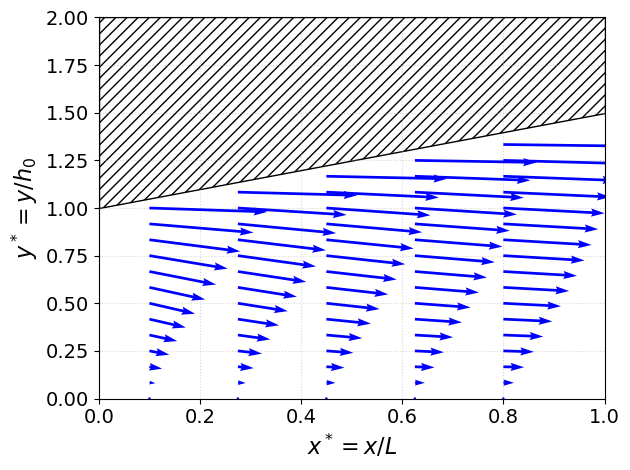

In [15]:
plot_func_vel(0.5)

Next, an [`interact`](https://ipywidgets.readthedocs.io/en/latest/examples/Using%20Interact.html) widget will let us vary $\alpha$.

In [16]:
interact(plot_func_vel, 
         α=widgets.FloatSlider(value=0.5, min=-0.9, max=2, step=0.05, description='Slope α'));

# FURTHER EXPLORATION

On your own:

*   Try different $h^*(x^*)$ shapes, such as
    -   $h^*(x^*) = e^{\alpha x^*}$.
    -   $h^*(x^*) = \begin{cases} 1, &0\le x^* \le 1/2,\\ \alpha, &1/2 < x^* \le 1.\end{cases}$
*   Calculate the lubrication force (per unit width out of the page) $W = \int_0^L p(x) - p_0 \, dx$.
    -   Make the force dimensionless. What dimensionless groups does it depend on?
    -   In this rigid-translation setup, how does it vary with $\alpha$?
    -   We say that the bearing can support a load $W$ (by a FBD on it) when $W>0$. So, for which ranges of $\alpha$ is $W>0$ based on what you calculated?
*   Hydroplaning: a tire tread element sliding over a wet road is lifted by a thin water film [(Moore, 1967)](https://doi.org/10.1016/0020-7403%2867%2990008-2). Model the gap as a parabola, $h(x) = h_0 + x^2/(2R)$, with $x=0$ at the narrowest point.
    -   Find $p(x)$ for $-a \le x \le b$. Show that $W=0$ when $a=b$.
    -   For which $a/b$ is $W>0$?
*   Challenge yourself: allow squeeze/approach motion (so $V_y \neq 0$ through the kinematic BC). How do $p$ and $W$ change then?

# REFERENCES

G. R. Hunt, J. P. Webb, A note on the kinematic boundary condition with historical perspective, _Am. J. Phys._ **94** (2026) 351&ndash;358. [doi:10.1119/5.0298780](https://doi.org/10.1119/5.0298780)

D. F. Moore, A theory of viscous hydroplaning, _Int. J. Mech. Sci._ **9** (1967) 797&ndash;810. [doi:10.1016/0020-7403(67)90008-2](https://doi.org/10.1016/0020-7403(67)90008-2)